
# Laboratorium 1: Poznaj swoje dane


W ramach naszych zajęć będziemy przechodzić przez kolejne warstwy systemu NLP:

`dane → baseline → reprezentacja → transformer → IE/NER → LLM → retrieval → RAG → ewaluacja`

Ten sam sposób myślenia będzie wracał na każdych zajęciach:

1. **pytanie badawcze,**
2. **hipoteza,**
3. **eksperyment,**
4. **metryka,**
5. **analiza błędów,**
6. **wniosek.**


> **Pytanie badawcze na dziś:** zanim wybierzemy model, czy wiemy, na jakich danych będziemy go trenować i testować?




## Po tych zajęciach student potrafi:

- wykonać podstawowy EDA dla danych tekstowych;
- sprawdzić rozkład klas i długości tekstów;
- wykryć puste rekordy, duplikaty (i potencjalne duplikaty);
- sprawdzić, czy między `train`, `validation` i `test` nie ma wycieku danych (data leakage);
- zbudować powtarzalny split i zapisać jego manifest;
- przygotować prostą kartę opisową zbioru;
- odróżnić problem modelu od problemu danych.

### Zasada na dziś

> **Podejrzanie dobry wynik jest powodem do szczegółowej ewaluacji, nie do świętowania.**



## Dane: PolEmo 2.0 / KLEJ

Pracujemy na polskich recenzjach konsumenckich z zadania [PolEmo 2.0](https://huggingface.co/datasets/allegro/klej-polemo2-in) w benchmarku KLEJ.

Klasy sentymentu:

- `plus`: pozytywny,
- `minus`: negatywny,
- `zero`: neutralny,
- `amb`: niejednoznaczny.

Repozytorium danych:  
https://huggingface.co/datasets/allegro/klej-polemo2-in

Publikacja KLEJ:  
https://arxiv.org/abs/2005.00630

Licencja zbioru na Hugging Face: CC BY-SA 4.0.

> **Ważne:** w projekcie produkcyjnym sprawdzamy nie tylko jakość danych, ale również ich pochodzenie, licencję, warunki redystrybucji i możliwość przetwarzania.



## Ustawienia wstępne

Do laboratorium wystarczy klasyczny stack Data Science.

Jeśli pracują Państwo w izolowanym / nowym środowisku:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow
```

In [1]:

from pathlib import Path
import hashlib
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 50)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)



## 1. Pobranie danych

Ładujemy oficjalne splity. Podział danych jest częścią eksperymentu, a nie technicznym szczegółem.


In [2]:
# TODO: ładowanie splitów datasetu (pliki train.csv, valid.csv, test.csv w repozytorium HF)
#
# Po tej komórce MUSZĄ istnieć (używają ich dalsze komórki):
#   URLS        - dict: split -> URL pliku
#   splits      - dict: "train" / "validation" / "test" -> DataFrame z kolumnami text, target, split
#   train_df, val_df, test_df
#   SPLIT_SIZES - dict: split -> liczba rekordów
#   CLASSES     - lista klas
#   LABEL_MAP   - dict: oryginalna etykieta -> plus / minus / zero / amb

# Uwaga: nazwy kolumn w pliku źródłowym mogą różnić się od nazw używanych w notatniku.


base_repo_url = "https://huggingface.co/datasets/allegro/klej-polemo2-in/resolve/main/"
URLS = {
    "train": base_repo_url + "train.csv",
    "validation": base_repo_url + "valid.csv",
    "test": base_repo_url + "test.csv",
}

LABEL_MAP = {
    "__label__meta_plus_m": "plus",
    "__label__meta_minus_m": "minus",
    "__label__meta_zero": "zero",
    "__label__meta_amb": "amb",
}
CLASSES = ["plus", "minus", "zero", "amb"]

raw_splits = {name: pd.read_csv(url) for name, url in URLS.items()}

splits = {}
for name, raw in raw_splits.items():
    df = raw.rename(columns={"sentence": "text"})
    df["target"] = df["target"].map(LABEL_MAP)
    df["split"] = name
    splits[name] = df[["text", "target", "split"]]

train_df, val_df, test_df = splits["train"], splits["validation"], splits["test"]
SPLIT_SIZES = {name: len(df) for name, df in splits.items()}

In [3]:
train_df.head()

,text,target,split
0,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,plus,train
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,minus,train
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",amb,train
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",zero,train
4,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,plus,train


In [4]:
SPLIT_SIZES

{'train': 5783, 'validation': 723, 'test': 722}


# Zadanie 1: Sanity check danych

Zanim zrobią Państwo coś bardziej zaawansowanego, proszę odpowiedzieć na pytanie:

1. Jakie kolumny zawiera zbiór?
2. Jaki jest typ każdej kolumny?
3. Czy liczba rekordów zgadza się między źródłem a tym, co faktycznie wczytaliśmy?
4. Czy występują wartości brakujące?
5. Czy etykiety mają ten sam zbiór wartości w każdym splicie? Jeśli nazwy etykiet są nieczytelne, proszę zdefiniować `LABEL_MAP` (np. `__label__meta_plus_m` → `plus`) i zapisać go w manifeście.
6. Czy są rekordy z pustym albo bardzo krótkim tekstem?

### Do wykonania

Proszę uzupełnić komórkę poniżej. Wynik powinien zawierać jedną małą tabelę ewaluacyjną per split.


In [5]:
# TODO: sanity check dla train / validation / test.
#
# Minimalne kolumny tabeli:
# - split
# - rows
# - columns
# - missing_text
# - missing_target
# - unique_labels
#
# Wskazówka:
# display(df.isna().sum())
# display(df["target"].value_counts(dropna=False))

audit_rows = []

# MIEJSCE NA KOD
expected_sizes_from_repo_website = {"train": 5783, "validation": 723, "test": 722}
too_little_text_threshold = 10

for split_name, split_df in splits.items():
    actual_size = SPLIT_SIZES[split_name]
    audit_rows.append({
        "split": split_name,
        "rows": actual_size,
        "is_expected_rows_correct": actual_size == expected_sizes_from_repo_website[split_name],
        "columns": len(split_df.columns),
        "column_names": list(split_df.columns),
        "dtypes": split_df.dtypes.to_dict(),
        "missing_text": split_df["text"].isna().sum(),
        "missing_target": split_df["target"].isna().sum(),
        "unique_labels": sorted(split_df["target"].unique()),
        "text_with_less_than_10_chars": (split_df["text"].str.len() < too_little_text_threshold).sum(),
    })

pd.DataFrame(audit_rows)

,split,rows,is_expected_rows_correct,columns,column_names,dtypes,missing_text,missing_target,unique_labels,text_with_less_than_10_chars
0,train,5783,True,3,"[text, target, split]","{'text': str, 'target': str, 'split': str}",0,0,"[amb, minus, plus, zero]",1
1,validation,723,True,3,"[text, target, split]","{'text': str, 'target': str, 'split': str}",0,0,"[amb, minus, plus, zero]",0
2,test,722,True,3,"[text, target, split]","{'text': str, 'target': str, 'split': str}",0,0,"[amb, minus, plus, zero]",0


1. Każdy ze zbiorów zawiera 3 kolumny: tekst, labelka oraz rodzaj splitu. 
2. Wszystkie kolumny są typu string. 
3. Liczba rekordów zgadza się dla każdego splitu.
4. W żadnym splitcie nie mamy brakujących danych. Ani w kolumnie tekst ani w kolumnie labelek. 
5. Etykiety mają ten sam zbiór wartości w każdym splitcie
6. W splitcie `train` jest jeden rekord z tekstem bardzo krótkim (ponieżej 10 znaków). Zbadam go poniżej:

In [6]:
for split_name, split_df in splits.items():
    bad = split_df[split_df["text"].isna() | (split_df["text"].str.strip().str.len() < too_little_text_threshold)]
    if not bad.empty:
        print(f"Split: {split_name}")
        display(bad[["text", "target"]])

Split: train


,text,target
4476,P,amb


Wiersz z małą ilością znaków to litera P. Jest ona traktowana jako `ambigues`. 


## Hipoteza 1

Czy dane są zbalansowane?

Zanim sporządzą Państwo wykres, proszę sformułować hipotezę.

> „Spodziewam się, że `ambigues` oraz `zero` będzą klasami dominującymi, ponieważ opinie często są na ludziach "wymuszane" (dostajemy popupy, żeby wyrazić opinię) o czym świadczy powyższa opinia z pojedynczym znakiem P, stąd ludzie często nie pomyślą dogłębnie nad wyborem strony ale po prostu napiszą coś dla samej sztuki pisania, bez głębszego sensu.”


# Zadanie 2: Rozkład klas

Proszę policzyć:

- liczebność klas,
- udział procentowy klas,
- rozkład osobno dla `train`, `validation`, `test`.

Następnie proszę odpowiedzieć:

1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach?
2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę?
3. Czy rozkłady klas między splitami są podobne?


In [7]:

# TODO: tabela rozkładu klas dla każdego splitu

class_distribution = {}
for split_name, split_df in splits.items():
    counts = split_df["target"].value_counts()
    class_distribution[split_name] = counts
    percentages = counts / len(split_df) * 100
    df = pd.DataFrame({
        "count": counts,
        "percentage (%)": percentages.round(2)
    })
    print(f"Rozkład klas dla splitu '{split_name}':")
    display(df)

Rozkład klas dla splitu 'train':


,count,percentage (%)
target,,
minus,2194,37.94
plus,1568,27.11
amb,1050,18.16
zero,971,16.79


Rozkład klas dla splitu 'validation':


,count,percentage (%)
target,,
minus,271,37.48
plus,209,28.91
zero,127,17.57
amb,116,16.04


Rozkład klas dla splitu 'test':


,count,percentage (%)
target,,
minus,300,41.55
plus,197,27.29
zero,117,16.20
amb,108,14.96


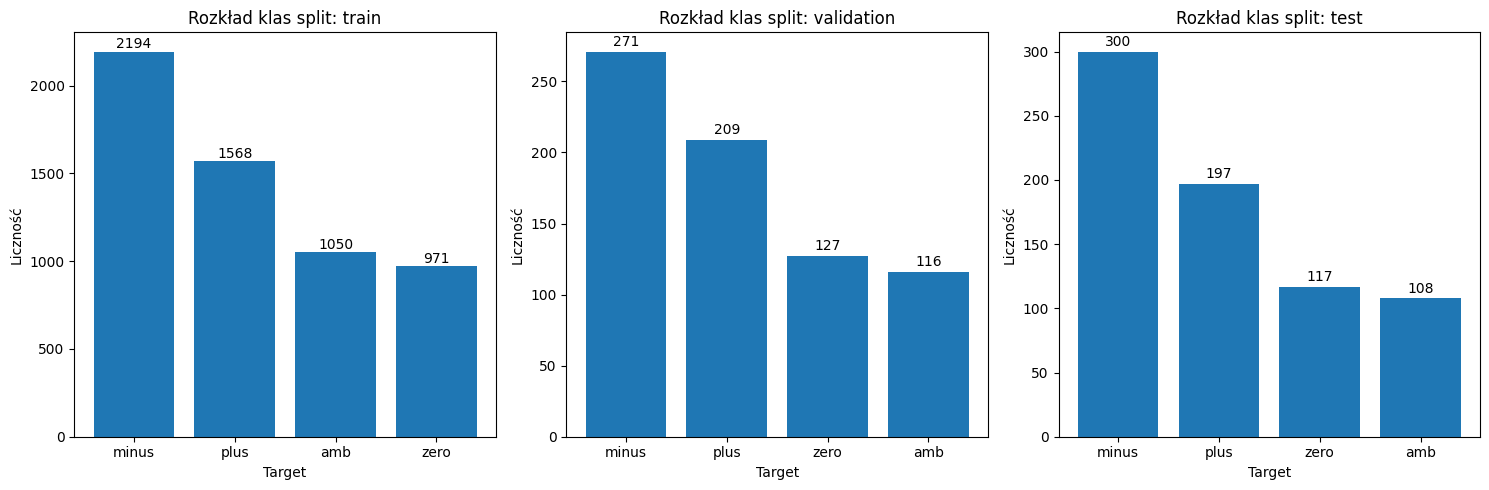

In [8]:

# TODO: wykres rozkładu klas

# MIEJSCE NA KOD
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
i = 0
for name, counts in class_distribution.items():
    bars = ax[i].bar(counts.index.astype(str), counts.values)
    
    ax[i].set_title(f"Rozkład klas split: {name}")
    ax[i].set_xlabel("Target")
    ax[i].set_ylabel("Liczność")
    
    for bar in bars:
        height = bar.get_height()
        ax[i].text(bar.get_x() + bar.get_width() / 2., height + 2, str(int(height)), ha='center', va='bottom')   
    i += 1

plt.tight_layout()
plt.show()

1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach?

Nie. Klasy sa niezbalansowane, mamy wyraźnie dominującą klasę `minus` i wyraźnie mniejsze liczebnie klasy `zero` oraz `amb`. Accuracy nie działa dobrze dla zbioru z niezrównoważonymi klasami. Dla takiego zbioru lepiej sprawdza się np. metryka f1-score.

2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę?

Osiągnąłby ok. 40% accuracy (klasa `minus` to 37.9% w train, ale aż 41.6% w test, więc na zbiorze testowym taki klasyfikator trafiłby ok. 41.6%).

3. Czy rozkłady klas między splitami są podobne?

W miarę tak — ogólny kształt rozkładu jest zachowany (wszędzie dominuje `minus`, najmniej liczne są `zero`/`amb`). Różnice sięgają jednak ok. 3–4 punktów procentowych: `minus` to 37.9% w train, 37.5% w validation i 41.6% w test, a `amb` spada z 18.2% w train do 15.0% w test. To niewielkie, ale zauważalne przesunięcie (test ma więcej `minus`).

Ogólnie moja hipoteza się nie sprawdziła. Ludzie najwyraźniej najbardziej lubią narzekać i wystawiać negatywne opinie  (ok. 40% opinii !!!). To chyba lepiej niż być leniwym.



# Zadanie 3: Jak wygląda „typowy tekst”?

Długość tekstu jest jednym z pierwszych parametrów, które warto sprawdzić.

Dp wyświetlania tekstu proszę dodać cechy:

- `n_chars`: liczba znaków,
- `n_words`: liczba słów (regex `\w+`) oraz `n_words_split` (`split()` po białych znakach),
- `n_lines`: liczba linii.

Proszę policzyć co najmniej:

- minimum,
- medianę,
- średnią,
- 90. percentyl,
- 95. percentyl,
- 99. percentyl,
- maksimum.

Następnie proszę obejrzeć (i zanotować wnioski z obserwacji):

- 5 najkrótszych tekstów,
- 5 najdłuższych tekstów.

### Pytania

- Czy ekstremalnie długi dokument zawsze jest błędem?
- Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?
- Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?

In [9]:
all_df = pd.concat(splits.values(), ignore_index=True)

# TODO: do dodania n_chars, n_words, n_words_split, n_lines.

# MIEJSCE NA KOD
all_df["n_chars"] = all_df["text"].str.len()
all_df["n_words"] = all_df["text"].str.count(r"\w+")
all_df["n_words_split"] = all_df["text"].str.split().str.len()
all_df["n_lines"] = all_df["text"].str.count("\n") + 1
all_df.head()

,text,target,split,n_chars,n_words,n_words_split,n_lines
0,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,plus,train,681,121,126,1
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,minus,train,663,97,107,1
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",amb,train,304,48,50,1
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",zero,train,917,158,156,1
4,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,plus,train,570,103,109,1


In [10]:
# TODO: tabela statystyk długości

# MIEJSCE NA KOD
metrics = ["n_chars", "n_words", "n_words_split", "n_lines"]

global_stats = pd.DataFrame({
    col: {
        "min": all_df[col].min(),
        "median": all_df[col].median(),
        "mean": all_df[col].mean(),
        "p90": all_df[col].quantile(0.90),
        "p95": all_df[col].quantile(0.95),
        "p99": all_df[col].quantile(0.99),
        "max": all_df[col].max()
    } for col in metrics
}).T.round(2)

display(global_stats)

,min,median,mean,p90,p95,p99,max
n_chars,1.0,696.0,777.01,1294.0,1605.65,2335.19,5391.0
n_words,1.0,121.0,135.22,227.0,286.65,420.46,920.0
n_words_split,1.0,121.0,136.32,228.0,288.65,414.73,987.0
n_lines,1.0,1.0,1.00,1.0,1.00,1.00,1.0


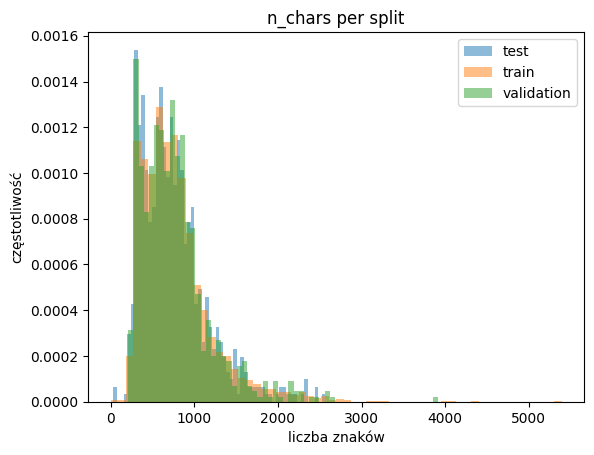

In [11]:
# TODO: histogram długości tekstów

# MIEJSCE NA KOD
for name, g in all_df.groupby("split"):
    plt.hist(g["n_chars"], bins=60, alpha=0.5, density=True, label=name)
plt.title("n_chars per split")
plt.xlabel("liczba znaków")
plt.ylabel("częstotliwość")
plt.legend()
plt.show()

In [12]:
# TODO: skrajne obserwacje

# MIEJSCE NA KOD
display(all_df.nsmallest(5, "n_chars")[['target', "text"]].style.set_properties(**{
            'white-space': 'pre-wrap', 
            'word-break': 'break-word',
        }))
display(all_df.nlargest(5, "n_chars")[['target', "text"]].style.set_properties(**{
            'white-space': 'pre-wrap', 
            'word-break': 'break-word',
        }))

,target,text
4476,amb,P
7041,zero,Marka Baccarat Hotels & Res o
4310,minus,"Hotel , jak za tą kwotę ( 230 - 2 osoby & aut o"
7095,zero,W grudniu czterogwiazdkowy Hotel Korona Spa & Wel l
4538,minus,Hotel powinien nazywać się MARNIOR ( z uwagi na kiepska jakosc uslug ) & Gwa r


- Czy ekstremalnie długi dokument zawsze jest błędem?

Nie, jak widzimy na przykładach najdłuższych tesktów, są to zwyczajne, prawidłowe recenzje. Jak już coś, to te najkrótsze teskty mogą być problematyczne (jak nasz przykładowy wiersz z literą P)

- Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?

Długie teksty w procesie tokenizacji mogą zostać obcięte jeśli przekroczą limity długości narzucane przez modele, przez co jest możliwość utraty potrzebnych informacji. W batchu, przez długie teksty, będzie potrzebne dużo paddingu w batchach, co zmarnuje pamięć i czas. W chunkingu zbyt długi tekst może zostać podzielony na fragmenty.


- Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?

`n_words` <= `n_words_split` taka ogólnie zależność będzie w wyliczonych przez nas tokenach w tekście.

1. `n_words_split` - szukamy ilości tokenów w tekście, odzdzielając je znakami białymi (więc policzymy dodatkowo elementy jak: `&, %, -` jako osobne słowa)
2.  `n_words` - łapiemy słowa za pomocą regexu \w+, czyli pobierami tylko elementy które zkładają się z alfanumerycznych znaków (litery małe, duże i cyfry, bez znaków `&` czy `-`)

Różnice świadczą o istnieniu znaków interpunkcyjnych w tekstach. 


# Zadanie 4: Szum danych

Tekst naturalny nie jest sterylny.

Proszę sprawdzić, ile rekordów zawiera co najmniej jeden z poniższych elementów:

- URL,
- adres e-mail,
- sekwencję wielu wykrzykników lub znaków zapytania,
- dużo WIELKICH LITER,
- znaki nowej linii,
- tekst krótszy niż 20 znaków.

Proszę nie usuwać ich automatycznie!

> Najpierw wykrywamy zjawisko. Potem decydujemy, czy jest błędem, sygnałem czy częścią danych.

Proszę też sprawdzić, czy którakolwiek flaga szumu jest skorelowana z etykietą. Czy to sygnał, artefakt, czy shortcut?

In [13]:
def get_uppercase_ratio(text):
    letters = [c for c in str(text) if c.isalpha()]
    if not letters:
        return 0.0
    upper_count = sum(1 for c in letters if c.isupper())
    return upper_count / len(letters)

In [14]:
# TODO: proszę obliczyć poniższe flagi bool
#
# has_url, has_email, has_punct_burst, has_newline, is_very_short, high_uppercase
#
# Proponowany próg high_uppercase: uppercase_ratio > 0.5,
# zaleca się eksperyment z tym progiem.
#
# UWAGA: w tym zbiorze interpunkcja jest oddzielona spacjami (np. "! ! !"),
# więc prosty wzorzec [!?]{2,} jej nie wykryje.

noise_flags = ["has_url", "has_email", "has_punct_burst", "has_newline", "is_very_short", "high_uppercase"]

url_regex = r"https?://(?:[-\w.]|(?:%[\da-fA-F]{2}))+[^\s]*"
email_regex = r"[\w.+-]+\s?@\s?[\w-]+\s?\.\s?[a-z]{2,}"
punct_burst_regex = r"[!?](?:\s*[!?]){2,}"
uppercase_ratio = 0.5


all_df["has_url"] = all_df["text"].astype(str).str.contains(url_regex)
all_df["has_email"] = all_df["text"].astype(str).str.contains(email_regex)
all_df["has_punct_burst"] = all_df["text"].astype(str).str.contains(punct_burst_regex)
all_df["has_newline"] = all_df["text"].astype(str).str.contains("\n")
all_df["is_very_short"] = all_df["n_chars"] < 20
all_df["uppercase_ratio"] = all_df["text"].apply(get_uppercase_ratio)
all_df["high_uppercase"] = all_df["uppercase_ratio"] > uppercase_ratio
all_df["any_noise"] = all_df[noise_flags].any(axis=1)

flags_to_display = noise_flags + ["any_noise"]
noise_summary = pd.DataFrame({
    "liczba_rekordow": [all_df[flag].sum() for flag in flags_to_display],
    "procent (%)": [(all_df[flag].sum() / len(all_df)) * 100 for flag in flags_to_display]
}, index=flags_to_display).round(2)
display(noise_summary)

,liczba_rekordow,procent (%)
has_url,5,0.07
has_email,5,0.07
has_punct_burst,657,9.09
has_newline,0,0.00
is_very_short,1,0.01
high_uppercase,10,0.14
any_noise,670,9.27


Największym problemem w danych jest interpunkcja. Ten problem dotyczy prawie 10% teskstów. Zobaczmy przykłady problematycznych rekordów:

In [15]:
display(all_df.loc[all_df["has_url"], ["target", "text"]].head(5).style.set_properties(**{
            'white-space': 'pre-wrap', 
            'word-break': 'break-word',
        }))

,target,text
782,zero,"Dodatkowo w najbliższych latach nadal będzie istnieć możliwość poddawania się kolonoskopii przesiewowej bez zaproszenia ( tzw . system oportunistyczny ) . Mogą się na nią zgłaszać – samodzielnie lub z polecenia lekarza podstawowej opieki zdrowotnej osoby w wieku 50 - 65 lat , nie mające objawów mogących świadczyć o obecności raka jelita grubego , jak krwawienie z przewodu pokarmowego ( krew w kale ) , biegunka lub zaparcia , które wystąpiły w ostatnich kilku miesiącach i nie mają znanej przyczyny , a także chudnięcie czy anemia o niewyjaśnionym podłożu . Prof . Reguła zaznaczył , że osoby z takimi objawami powinny podlegać badaniom diagnostycznym ( w tym kolonoskopii ) , ale finansowanym przez NFZ , a nie w ramach programu profilaktycznego , który finansuje Ministerstwo Zdrowia . Informacje na temat ośrodków , do których można się zgłaszać na kolonoskopię przesiewową znajdują się na stronie internetowej Programu Badań Przesiewowych ( http://pbp.org.pl ) ."
1486,plus,"Informacje , które można znaleźć w internecie : Dr n . med . Bożenie Dołyk Specjalizacja : neurologia dziecięca Inne : certyfikat Międzynarodowego Stowarzyszenia Vojty ( IVG ) z zakresu diagnostyki metodą Vojty z prawem nauczania diagnostyki , certyfikat IVG z zakresu terapii Vojty . Komentarz z forum BabyBoom z lipca 2005 : "" Wszystkim matkom które chcą mieć NAPRAWDĘ ZDROWE DZIECKO polecamy Panią doktor Bożenę Dołyk - fachowe podejście i wogóle rewelacja . "" ( http://www.babyboom.pl/forum/zlota-lista-f51/czarna-lista-1846/index6.html#post_message_82728 )"
1525,zero,"Zorganizowano ją w ramach obchodów Polskiego Dnia Spirometrii , który przypada 27 czerwca . Z tej okazji w ponad 150 placówkach medycznych w całym kraju będzie można bezpłatnie wykonać spirometrię . Więcej informacji na ten temat można znaleźć na stronie Polskiej Federacji Stowarzyszeń Chorych na Astmę i POChP , które jest inicjatorem akcji badań ( http://www.astma-alergia-pochp.pl ) . Jak przypomniał prezes Federacji dr Piotr Dąbrowiecki , spirometria pozwala wykryć obturację , czyli zwężenie oskrzeli . „ Na schorzenia , którym towarzyszy obturacja cierpi w Polsce ok . 6 mln chorych – w tym 4 mln na astmę , a 2 mln na przewlekłą obturacyjną chorobę płuc ( POChP ) ” – podkreślił . Dodał , że u połowy z nich ( w tym u 2 mln z astmą i co najmniej 1 mln z POChP ) schorzenie nie jest jeszcze rozpoznane i prawidłowo leczone ."
2083,zero,"Tak czy inaczej genetyczne pasożyty robią w naszym genomie niezły bałagan . "" Aż 17 proc . DNA w ludzkim genomie to elementy LINE - 1 kodujące tzw . retrotranspozony "" – powiedział . Jego zespół złożony z młodych naukowców , dr . Zbigniewa Warkockiego - pierwszego autora publikacji , dr . Pawła Krawczyka i Doroty Adamskiej opublikował właśnie w prestiżowym piśmie "" Cell "" artykuł pokazujący nieznany dotąd sposób , w jaki komórka może blokować tych małych genowych spryciarzy przed dalszym namnażaniem ( https://doi.org/10.1016/j.cell.2018.07.022 ) . Jak wyjaśnił naukowiec , każdy z nas ma w swoich komórkach między 80 a 100 aktywnych retrotranspozonów . "" Nie są nam do niczego potrzebne , wręcz są szkodliwe "" - mówi naukowiec . Wklejając się do DNA prowadzą do powstawania mutacji , często towarzyszą nowotworzeniu lub wręcz leżą u jego podstaw ."
3161,minus,"Zarezerwowali śmy w marcu pokój na sierpień ( 4 dni ) . Cena miała wynosić 90zł za dobę . Na miejscu zostali śmy poinformowani , że ten pokój kosztuje 170zł , ale promocyjnie wynajmą go nam za 140zł . Ponadto pracownicy nie wiedzieli nawet na jak długo przyjechali śmy , w systemie mieli podany pobyt jednodniowy . Poprosili śmy o kontakt z kierownikiem , co spotkało się z kategoryczną odmową aroganckiego i bezczelnego personelu . Poprosili śmy o oficjalny cennik , ale również nas zbyto . Poinformowano nas , że kierownik ma prawo robić co chce , bo to jego hostel , nie musi nas informować o zmianie cen , bo to w naszym obowiązku leży zadzwonić 2 dni przed przyjazdem i zapytać , czy ta rezerwacj

In [16]:
display(all_df.loc[all_df["has_email"], ["target", "text"]].head(5).style.set_properties(**{
            'white-space': 'pre-wrap', 
            'word-break': 'break-word',
        }))

,target,text
956,zero,"witaj mała : ) narazie sie nie staram o dziecko , jeszcze troszkę za wczesnie lecz juz mam obawy co do przyszłego leczenia , czy bedzie ono skutecznie . też chodziła m po różnych ginekologach z NFZ i zero rozpoznania a tym samym zero leczenia . . . za namową przyszłej teściowej poszła m jeszcze na konsultacje do innego ginekologa z nfz i powiedział ze ta choroba nie jest do leczenia w przychodni i dał mi wizytówke innego lekarza a mianowicie Grochowicza ktory podobno specjalizuje sie w leczeniu bezpłodności , może opinii nie ma za dobrych ale w przyszłym miesiacu sie do niego wybiore na konsultacje i wyjasnienie kilku wątpliwości , może mnie troszeczke uspokoi . . . jak coś pisz na mojego maila martinellka @ o2 . pl"
2806,plus,"Po zaskakująco ładnym widokowo transferze z lotniska dotarli śmy do hotelu skąpanego w zieleni i serdecznie uśmiechniętą obsługę recepcji . Od razu dostali śmy coś do picia i błyskawicznie dostali śmy klucze do pokoju , od razu personel zaprowadził nas do pokoju ! ! Pokój zaskoczył nas wielkością i funkcjonalnością łazienka mała ale funkcjonalna kotarka prysznicowa trochę irytowała ale . . . . . , zaskoczyło nas że od razu na drugi dzień pokój został dokładnie posprzątany mimo że dzień wcześniej lśnił czystością a panie sprzątające zawsze uśmiechnięte ! ! Restauracja zawsze czysta nigdy niczego nie brakło wybór potraw zadowoli , mięsa wszelakie ciekawe smaki czasem zaskakujące , potrawy czysto greckie musaka ciasto filo z rożnymi farszami , zapiekanki baranina królik kurczak indyk szef kuchni kroił a to udziec alko kaczkę w całości a bar sałatkowy nigdy nie był pusty a sery hmmmm . Baseny czyste dwa głębokie można popływać i jeden dla dzieci płytki , z leżakami raczej nie było problemu choć warto było położyć ręcznik by mieć parasol dla cienia ! Bary dwa ale jeden czynny do 23 i tu mały problem bo kolejki i jedna z barmanek troszkę kapryśna ale . . . . . za to w mniejszym barze przy basenie dla dzieci o imieniu Eleni zawsze uśmiechnięta i pracowita miło było posiedzieć ! ! ! Plaża blisko w dół od hotelu po drodze market sama plaża średnia kamienie i trochę piachu mały minus woda krystalicznie czysta ale chłodniejsza niż w innych miejscach na wyspie jak psili amos potami papa beach czy liwadaki ale spokojnie można popływać . Sama wyspa zielona ale górzysta i choć drogi w dobrym stanie to kręte i czasami strome , mając samochód z wypożyczalni można w 4 dni odwiedzić sporo ciekawych miejsc polecam wypożyczalnie Action około 100 m do marketu w dół prowadzi ją polak Paweł super gość i profesjonalna obsługa i autka pewne na 100 % . Jeśli czegoś nie napisał em czekam na pytanie pod adresem stiwen11 @ interia . pl na pewno odpiszę pozdrawiam Sławomir !"
4235,amb,"Przełom 06 / 07 2016 . Forma "" All inclusive "" Po pierwsze nie powinno nazywac się to "" all inclusive "" w hotelu robią wszystko żeby za coś płacić , począwszy od wi _ fi w pokoju przez płatne restauracje w hotelu po główny bar , bar na plaży i leżaki na plaży . Wi - Fi nie płatne w holu głównym ale to nie plus bo byle restauracja ma Wi - Fiw ramach spożywanego tam posiłku ; , bar w holu głównym z wygodnymi fotelami płatny , bar all inclusive piętro niżej wciśnięty w kąt z ciasno ustawionymi metalowoplastikowymi krzesełkami ; bar i leżaki w centrum plaży płatny , bar all inclusive oddalony od leżaków od 120 do 50 m po gorącym piasku , wokół baru brak stolików czy też samych stołków _ podobno nie ma miejsca ! ( w promieniu 70m piasek ) do soku np . pomarańczowego dolewają wody bo podobno za słodki ! ! ! ! Obsługa pokojowa zapomina uzupełnić płyn pod prysznic , szampon , zamiast trzech ręczników daje dwa , a nawet brakuje papieru toaletowego ! ! ! Heloo ! ! ! ! Ten hotel ma 5 gwiazdek ! ! ! Jedzenie : duży wybór , smacznie , natomiast wołowina i wieprzowina twarda jak podeszwa reszta jedzenia ok . Sam hotel robi KOLOSALNE wrażenie ! ! ! ! ! JEST WIELKI PIĘKNY MONUMENTALNY ! ! ! Wrażenie niezapomniane ! ! ! Pokoje ładne duże prze

Rzeczywiście w każdym z zaprezentowanych przykładów znajdują się linki, maile, więc regexy sa najprawdopodobniej poprawne.

In [17]:
display(all_df.loc[all_df["has_punct_burst"], ["target", "text"]].head(5).style.set_properties(**{
            'white-space': 'pre-wrap', 
            'word-break': 'break-word',
        }))

,target,text
14,minus,"Przeszła m zabieg korekty powiek górnych u doktora Ibrahima ponad rok temu . Operacja poskutkowała lekką poprawą wyglądu powiek ( daleką od spodziewanej ) a skutkiem ubocznym są bardzo duże blizny . Na lewym oku blizna sięga skroni ! ! ! To była moja pierwsza i jedyna operacja plastyczna , więc nie wiedziała m dokładnie czego się spodziewać . Konsultacja przedzabiegowa była pośpieszna . Recepcjonistka poinformowała mnie przed zabiegiem , że dostanę tzw . niebieską pigułkę na zobojętnienie , jednak nikt mi jej nie podał . Ogólnie w klinice panowała atmosfera pośpiechu i braku organizacji . Podczas operacji doktorowi asystowali pielęgniarze , którzy w ogóle nie mówili po polsku i słabo po angielsku wiéc komunkacja była bardzo utrudniona . Bardzo mocno uciskali moje oczy , żeby wyjąć woreczki tłuszczowe , musiała m prosić doktora o zwrócenie im uwagi . Doktor zainterweniował , ale siniaki miała m przez cały miesiąc . Ale to jescze nic . Najgorsze , że moje powieki wyglądają , jakby przypadkowo pocięte . Blizny różnią się położeniem i długością . Teraz mam na powiekach blizny zanikowe idące w kierunku skroni , są nierówne , jedna jest dłuższa i leży wyżej od drugiej . Przy tak rozległych bliznach nie pomaga żaden makijaż , nawet specjalistyczny korygujący . Od ponad roku próbuję zabiegów laserowych , kremów , maści itp . Niestety wzystko to pomogło tylko trochę . Nieunikniony będzie zabieg rewizyjny . Doktor Ibrahim nie wykazał żadnej chęci pomocy po zaistniałej sytuacji . Stwierdził , że to moja wina , bo mam zaburzenia produkcji kolagenu . 3 lekarzy chirurgów u których była m na konsultacji w sprawie operacji rewizyjnej , nie potwierdziło jego opinii . Nie polecam tego lekarza ani kliniki Mandala ."
28,plus,"Polecam doktora z czystym sumieniem ! ! ! ! Prowadził moje trzy ciąże . Wykazał się ogromnym profesjonalizmem , empatią a przede wszystkim troską o moje Dzieci . Wizyty raz w miesiącu pozwalają dokładnie kontrolować i śledzić rozwój , poczynania Dzidziusia ponieważ na każdej wizycie miała m robione usg co jest dużym plusem . Cennik jak na Warszawę uważam za atrakcyjny . Do samego rozwiązania byli śmy w kontakcie z doktorem i nigdy nie dał mi odczuć , że dzwonię w nieodpowiednim momencie czy że przeszkadzam . . . Gdy nie mógł rozmawiać zwyczajnie oddzwaniał kiedy tylko mógł . Na oddziale jest również bardzo szanowanym lekarzem co również dało się odczuć . Jesteśmy bardzo zadowoleni i pewnie kolejną ciąże również poprowadzi . Bardzo Dziękujemy : ) AGMJ"
35,plus,"Witam . Ja miałem problem z ciągłym krwawieniem z nosa . Chodził em do innego laryngologa kilka lat i żadnego pozytywnego skutku to nie przyniosło , z każdą wizytą miałem zabieg "" przypalania "" w nosie . Po jakimś czasie dowiedział em sie od pani doktor że jak jeszcze raz zrobi mi ten zabieg to moge stracić węch ! ! ! Postanowił em szukać innego lekarza . Na szczęście polecono mi panią doktor Imburską . Bardzo dokładnie mnie przebadała i przepisała mi maść robioną za UWAGA ! ! ! 5 ZŁ ! ! ! i krwawienie przeszło ! ! ! POLECAM GORĄCO TEGO LEKARZA ! ! ! !"
64,minus,"Podczas wizyty lekarz ten bardziej interesował się swoim telefonem niż mną ! Zamiast skupić się na badaniu bez jakichkolwiek obiekcji i skrępowania czytał przychodzące smsy ! ! ! ! ! Zadając mu pytania oczekiwała m jasnych odpowiedzi , jednak wielokrotnie zwyczajnie mnie zbywał . . . Po ostatniej wizycie jestem naprawdę rozczarowana . . . Nie polecam tego lekarza ! ! ! ! ! ! !"
74,plus,Pediatra od urodzenia ! ! ! Lekarz z powołania ! Bardzo miła i kompetentna kobieta . Mój syn ją uwielbia . Zawsze pomocna i służąca radą . Antybiotyk w ostateczności . Mój syn jest alergikiem a ona również jest pulmonologiem . Jest za naturalnym żywieniem dziecka ( żadnych słoiczków i kaszek sztucznie barwionych ) . Dziecko jest najważniejsze . Ogólnie o przychodni Sanus mam bardzo dobre zdanie np . jeżeli twój lekarz nie ma miejsca na dzisiaj to na pewno nie pozostawią cię bez opieki ( przyjmie cię inny

In [18]:
for flag in noise_flags:
    print(f"\n Korelacja flagi: {flag} z etykietą target")
    crosstab = pd.crosstab(all_df[flag], all_df["target"], normalize="index") * 100
    display(crosstab.round(2))


 Korelacja flagi: has_url z etykietą target


target,amb,minus,plus,zero
has_url,,,,
False,17.64,38.27,27.32,16.78
True,0.00,20.00,20.00,60.00



 Korelacja flagi: has_email z etykietą target


target,amb,minus,plus,zero
has_email,,,,
False,17.61,38.27,27.32,16.81
True,40.00,20.00,20.00,20.00



 Korelacja flagi: has_punct_burst z etykietą target


target,amb,minus,plus,zero
has_punct_burst,,,,
False,18.38,35.22,28.02,18.38
True,10.05,68.65,20.24,1.07


... (2 outputs left out)


 Korelacja flagi: is_very_short z etykietą target


target,amb,minus,plus,zero
is_very_short,,,,
False,17.61,38.26,27.31,16.81
True,100.00,0.00,0.00,0.00



 Korelacja flagi: high_uppercase z etykietą target


target,amb,minus,plus,zero
high_uppercase,,,,
False,17.64,38.24,27.31,16.82
True,10.00,50.00,30.00,10.00


Widzimy korelację liniową bardzo krótkich tekstów z etykietą `amb`. Korelacja jest również wysoka przy dużej ilości interpunkcji i etykiecie `minus` (prawie 70%). Występowanie urli w tekście może oznaczać, że etykieta wyniesie `zero` (60% korelacji).


# Zadanie 5: Duplikaty

Duplikat w danych treningowych nie zawsze jest problemem. Jednak duplikat między zbiorami train i test może zafałszować wyniki.

Zaczniemy od dwóch wersji tekstu:

1. `text_raw`: oryginał,
2. `text_norm`: wersja używana wyłącznie do oceny duplikatów.

Normalizacja:

- Unicode NFKC,
- lowercase,
- redukcja białych znaków,
- trim.

> Nie usuwamy interpunkcji i nie robimy agresywnego preprocessingu.


In [19]:
# TODO:
# preprocessing

# TODO:
# 1. jakie dokładne duplikaty text_raw,
# 2. jakie duplikaty text_norm,
# 3. 10 przykładowych grup duplikatów,
# 4. czy ten sam text_norm występuje w więcej niż jednym splicie?

# MIEJSCE NA KOD
def normalize_text(text):
    text = unicodedata.normalize("NFKC", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

all_df["text_raw"] = all_df["text"]
all_df["text_norm"] = all_df["text_raw"].apply(normalize_text)

raw_dup_mask = all_df.duplicated("text_raw", keep=False)    # keep=False, czyli każdy duplikat zaznaczamy jako True
norm_dup_mask = all_df.duplicated("text_norm", keep=False)
display(pd.DataFrame({
    "duplicated_records": [raw_dup_mask.sum(), norm_dup_mask.sum()],
    "dup_groups": [all_df.loc[raw_dup_mask, "text_raw"].nunique(), all_df.loc[norm_dup_mask, "text_norm"].nunique()],   # dla danej grupy teskstu wyliczamy ile duplikatow, czyli znajdziemy liczbe unikalnych tekstow w zduplikowanych grupach
    "extra_copies": [all_df.duplicated("text_raw").sum(), all_df.duplicated("text_norm").sum()],    # dla danej grupy teskstu wyliczamy ile duplikatow ( czyli -1), bez orygnalnego rekordu
}, index=["text_raw", "text_norm"]).T)

,text_raw,text_norm
duplicated_records,0,0
dup_groups,0,0
extra_copies,0,0


Nie mamy żadnych duplikatów pomiędzy tekstami w żadnym ze zbiorów.


## Funkcja `audit_split_leakage`

Proszę napisać funkcję:

```python
audit_split_leakage(df, text_col="text_norm", split_col="split")
```

która zwróci rekordy występujące w więcej niż jednym splicie.

W wyniku chcemy co najmniej:

- tekst / fingerprint,
- liczbę wystąpień,
- listę splitów,
- etykiety.

To będzie pierwszy element naszej semestralnej biblioteki ewaluacyjnej.

In [20]:
def audit_split_leakage(df, text_col="text_norm", split_col="split"):
    result = (
        df.groupby(text_col)
        .agg(# dla każdego unikalnego tekstu wyliczamy
            liczba_wystapien=(split_col, "size"),
            splity=(split_col, lambda x: sorted(x.unique())),
            etykiety=("target", lambda x: sorted(x.unique()))
        )
        .reset_index()
    )

    result = result[result["splity"].apply(len) > 1]

    return result.sort_values("liczba_wystapien", ascending=False)

leakage = audit_split_leakage(all_df)
leakage

,text_norm,liczba_wystapien,splity,etykiety


Na tym zbiorze danych nie mamy wycieku między splitami. Nie ma zagrożenia, że model w zbiorze testowym zobaczy ten sam przykład, którego nauczył się w zbiorze treningowym. Dla tego przykładu nie ma ryzyka zawyżenia wartości metryk w ten sposób.


# Zadanie 6: Prawie duplikaty

Exact match nie wystarczy.

Przykład:

- `Świetny hotel. Polecam!`
- `Świetny hotel - polecam!!!`

Dla człowieka to prawie ten sam tekst. Hash ich nie połączy.

Na próbce danych proszę zbudować prosty detektor zdań, które są prawie duplikatami:

1. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`,
2. `NearestNeighbors(metric="cosine")`,
3. dla każdego tekstu proszę znaleźć najbliższego **innego** sąsiada (uwaga: przy `n_neighbors=1` sąsiadem jest zwykle ten sam dokument, więc pobierz kilku i pomiń siebie),
4. proszę policzyć podobieństwo jako `1 - cosine_distance`,
5. proszę policzyć pary z podobieństwem np. `>= 0.90`, osobno w obrębie jednego splitu i między splitami.

### Nie chodzi o idealny deduplikator

Celem jest zobaczenie, że decyzja "duplikat / nie duplikat" sama może być problemem modelowym.

In [21]:
# TODO nearest_other_neighbour

# MIEJSCE NA KOD
# j, sim = nearest_other_neighbor(X)
# pairs["cross_split"] = sample["split"].values[pairs["i"]] != sample["split"].values[pairs["j"]]

"""Funkcja znajduje najbliższego sąsiada dla każdego tekstu w zbiorze danych. 
"""
def nearest_other_neighbor(X, n_neighbors=5):
    n_samples = X.shape[0]
    if n_samples < 2:
        raise ValueError("Minimum 2 texts required.")

    nn = NearestNeighbors(n_neighbors=n_neighbors, metric="cosine")
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    nearest_indices = np.empty(X.shape[0], dtype=int)
    nearest_similarities = np.empty(X.shape[0], dtype=float)
    for i in range(X.shape[0]):
        for d, j in zip(distances[i], indices[i]):  # sąsiedzi są posortowani od najbliższego do najdalszego, więc zabieramy pierwszego najbliższego, który nie jest nami
            if j != i:  # znaj
                nearest_indices[i], nearest_similarities[i] = j, 1 - d
                break

    return nearest_indices, nearest_similarities

sample = all_df.reset_index(drop=True)
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
X = vectorizer.fit_transform(sample["text_norm"])
j, sim = nearest_other_neighbor(X)

In [22]:
pairs = pd.DataFrame({
    "i": np.arange(len(sample)),
    "j": j,
    "similarity": sim,
})
# układami wartości kolumny 'split' według kolejności wierszy w DataFrame pairs
pairs["cross_split"] = sample["split"].values[pairs["i"]] != sample["split"].values[pairs["j"]] 
pairs

,i,j,similarity,cross_split
0,0,36,0.262277,False
1,1,559,0.230594,False
2,2,997,0.224554,False
3,3,5799,0.238518,True
4,4,1032,0.237910,False
...,...,...,...,...
7223,7223,5621,0.324150,True
7224,7224,4297,0.279389,True
7225,7225,5263,0.253739,True
7226,7226,5647,0.238685,True


In [23]:
being_neighbbour_threshold = 0.9
near_duplicates = pairs[pairs["similarity"] >= being_neighbbour_threshold].copy()
print(f"Liczba par z podobieństwem min {being_neighbbour_threshold} w obrebie jednego splitu: {len(near_duplicates[~near_duplicates['cross_split']])}")
print(f"Liczba par z podobieństwem min {being_neighbbour_threshold} w różnych splitach: {len(near_duplicates[near_duplicates['cross_split']])}")

Liczba par z podobieństwem min 0.9 w obrebie jednego splitu: 4
Liczba par z podobieństwem min 0.9 w różnych splitach: 2


In [24]:
cross_split_dups = near_duplicates[near_duplicates['cross_split']].copy()
cross_split_dups["text_i_raw"], cross_split_dups["text_j_raw"] = sample["text_raw"].iloc[cross_split_dups["i"]].values, sample["text_raw"].iloc[cross_split_dups["j"]].values
cross_split_dups["split_i"],cross_split_dups["split_j"] = sample["split"].iloc[cross_split_dups["i"]].values, sample["split"].iloc[cross_split_dups["j"]].values

print(len(cross_split_dups))

display(cross_split_dups[["similarity", "split_i", "split_j", "text_i_raw", "text_j_raw"]].style.set_properties(**{
            'white-space': 'pre-wrap', 
            'word-break': 'break-word',
        }))

2


,similarity,split_i,split_j,text_i_raw,text_j_raw
1344,0.999948,train,test,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru Ramana . W celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik .","„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru Ramana . W celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik ."
6642,0.999948,test,train,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru Ramana . W celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik .","„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w p


# Zadanie 7: Czy split jest częścią danych?

Proszę porównać:

### A. oficjalny split
`train / validation / test`

### B. naiwny random split
po połączeniu wszystkich rekordów:

```python
train_test_split(..., stratify=target, random_state=42)
```

Nie trenujemy jeszcze modelu docelowego. Chcemy zobaczyć, czy sam sposób dzielenia danych może zmienić eksperyment.

Proszę sprawdzić dla obu wariantów:

- rozkład klas,
- exact duplicates między train/test,
- near-duplicates, jeśli masz czas.

### Pytanie

Czy losowy split jest zawsze metodologicznie poprawny?

Proszę pomyśleć o:

- użytkownikach,
- autorach,
- czasie,
- źródłach,
- dokumentach należących do tej samej sprawy,
- wielu fragmentach pochodzących z jednego dokumentu.


In [25]:
# MIEJSCE NA KOD
def split_report(train_part, test_part, name):
    same_text_between_splits = test_part["text_norm"].isin(set(train_part["text_norm"]))
    Xtr_vec = vectorizer.transform(train_part["text_norm"])
    Xte_vec = vectorizer.transform(test_part["text_norm"])
    nn = NearestNeighbors(n_neighbors=5, metric="cosine").fit(Xtr_vec)
    distances, _ = nn.kneighbors(Xte_vec)
    near_similarity = 1 - distances[:, 1] # pierwszy z dystansem mniejszym lub rownym 1 ( czyli pomijamy nas samych)
    return {
        "variant": name,
        "train_rows": len(train_part),
        "test_rows": len(test_part),
        **{f"train_{c}_%": round(100 * (train_part["target"] == c).mean(), 1) for c in CLASSES},
        **{f"test_{c}_%": round(100 * (test_part["target"] == c).mean(), 1) for c in CLASSES},
        "train_in_test_text": int(same_text_between_splits.sum()),
        "train_in_test_near_0.9": int((near_similarity >= 0.9).sum()),
    }

official_train = all_df[all_df["split"] == "train"]
official_test = all_df[all_df["split"] == "test"]
random_train, random_test = train_test_split(all_df,test_size=len(official_test),stratify=all_df["target"],random_state=42,)

pd.DataFrame([
    split_report(official_train, official_test, "official_split"),
    split_report(random_train, random_test, "random_split"),
]).set_index("variant")

,train_rows,test_rows,train_plus_%,train_minus_%,train_zero_%,train_amb_%,test_plus_%,test_minus_%,test_zero_%,test_amb_%,train_in_test_text,train_in_test_near_0.9
variant,,,,,,,,,,,,
official_split,5783,722,27.1,37.9,16.8,18.2,27.3,41.6,16.2,15.0,0,0
random_split,6506,722,27.3,38.3,16.8,17.6,27.3,38.2,16.9,17.6,0,0


Jak widzimy, rozkłady klas są bardzo podobne w splicie treningowym. A splicie testowym mamy większe różnice np. dla klasy `minus` albo dla klasy `amb`. Zarówno w oryginalnym podziale jak i w randomowym splicie nie mamy exact-duplicates tekstów jak i near-duplicates.

Jednak mimo, że w tym przypadku losowy split nie wskazuje na gorszą metodę podziału, moga byc przypadki, gdy jest nieporządaną metodą. np. może podzielić do splitu treningowego dużo opinii jednego autora, przez co późniejszy model nauczy się pewnej stylistyki i sposobu formułowana zdań, co może na zbiorze testowym, który nie ma opinii tego autora, pogorszyć wyniki.


# Zadanie 8: Eksperyment: wyciek danych potrafi „ulepszyć” model

Teraz użyjemy bardzo prostego klasyfikatora wyłącznie jako sondy diagnostycznej. Nie optymalizujemy hiperparametrów. To będzie temat kolejnego laboratorium.

Pipeline:

`TF-IDF → Logistic Regression`

Najpierw policzymy wynik na poprawnym splicie, a potem celowo zanieczyścimy train przykładami z testu.

### Hipoteza

Proszę sformułować przed uruchomieniem założenie:

> Jak zmieni się accuracy / macro-F1 po wprowadzeniu leakage i dlaczego?

Spodziewam się, że obie metryki się polepszą (zwiększą), ponieważ model "nauczy się na pamięć" tych leakowych przykładów.


In [26]:

probe = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

def evaluate_probe(train_part: pd.DataFrame, test_part: pd.DataFrame):
    probe.fit(train_part["text"], train_part["target"])
    pred = probe.predict(test_part["text"])
    return {
        "accuracy": accuracy_score(test_part["target"], pred),
        "macro_f1": f1_score(test_part["target"], pred, average="macro"),
    }

# Wynik bazowy na oficjalnym splicie:
clean_score = evaluate_probe(train_df, test_df)
clean_score


{'accuracy': 0.832409972299169, 'macro_f1': 0.7874406607152569}

In [27]:
# CELowo tworzymy błędny eksperyment: dokładamy część TESTU do TRAIN.
# Proszę nie robić tego nigdy w prawdziwej ewaluacji!!! :)

def score(model, part):
    pred = model.predict(part["text"])
    return accuracy_score(part["target"], pred), f1_score(part["target"], pred, average="macro")

rows = []
for frac in [0.0, 0.05, 0.10, 0.20, 0.50, 1.0]:
    leaked = test_df.sample(frac=frac, random_state=RANDOM_STATE)
    train_leaky = pd.concat([train_df, leaked], ignore_index=True)
    probe.fit(train_leaky["text"], train_leaky["target"])
    m = test_df.index.isin(leaked.index)
    row = {"leak_fraction": frac}
    row["acc_all"], row["f1_all"] = score(probe, test_df)
    row["acc_leaked"], row["f1_leaked"] = score(probe, test_df[m]) if m.any() else (np.nan, np.nan)
    row["acc_unleaked"], row["f1_unleaked"] = score(probe, test_df[~m]) if (~m).any() else (np.nan, np.nan)
    rows.append(row)

pd.DataFrame(rows)

,leak_fraction,acc_all,f1_all,acc_leaked,f1_leaked,acc_unleaked,f1_unleaked
0,0.00,0.832410,0.787441,NaN,NaN,0.832410,0.787441
1,0.05,0.837950,0.793298,0.916667,0.824472,0.833819,0.791456
2,0.10,0.840720,0.797268,0.944444,0.903195,0.829231,0.787687
3,0.20,0.854571,0.819503,0.951389,0.934320,0.830450,0.791605
4,0.50,0.890582,0.869299,0.952909,0.943915,0.828255,0.796047
5,1.00,0.959834,0.952110,0.959834,0.952110,NaN,NaN



## Analiza

Proszę odpowiedzieć krótko:

1. Jak duża była różnica dla każdej wartości leak_fraction?

Bez wycieku accuracy 0.832 i macro-F1 0.787. Przy 5% wycieku dla obu metryk +0.005, przy 10% ok. +0.01, przy 20% ok. +0.02, przy 50% ok. +0.05, a przy 100% accuracy osiąga 0.960 i F1 osiąga 0.952, czyli ok. +0.15 i +0.1.

2. Czy wynik wzrósł tak mocno, jak było oczekiwane?

Spodziewałam się większego wzrostu, szczególnie przy wycieku 100%, gdzie oczekiwałabym nuczenia się odpowiedzi na pamięć przez model i wartości praktywnie 100% dla obu metryk. Tym czasem są to wartości rzędu 95%.

3. Dlaczego wyciek przez duplikaty może być bardziej lub mniej szkodliwy zależnie od modelu?

Modele, które łatwo zapamiętują np. klasyfikatory jak kNN, drzewa, zyskają na wycieku dużo bardziej. Model liniowy z regularyzacją zapamiętuje słabiej, więc wyciek mniej w przypadku takiego modelu nas oszuka.

4. Czy wysoki wynik sam w sobie pozwala odróżnić dobry model od błędnej ewaluacji?

Nie. Patrząc na sam wynik nie zrobimy rozróżnienia. Musimy wykonac preprocessing danych i zanalizować leakage. 

5. Jakie testy automatyczne dobrze dodać do pipeline'u danych?

Sprawdzanie leakagów znormalizowanych tekstów (exact-duplicates oraz near-duplicates). Sprawdzenie rozkładu klas.

6. Czy wzrost wyniku wynika z zapamiętania wyciekłych rekordów (acc_leaked), czy z poprawy na pozostałych (acc_unleaked)?

Z zapamiętania wyciekłych rekordów. Wartości w kolumnie `acc_unleaked` pozostają bez zmian wraz z zwiększeniem wycieku.


# Zadanie 9: Dane do kolejnego laboratorium

Na następnych zajęciach będziemy budować baseline'y klasyfikacyjne. Proszę zatem przygotować czysty, wersjonowany artefakt.

### Minimalna polityka czyszczenia

Rekomendujemy:

- usunąć rekordy bez tekstu lub labelu,
- **nie modyfikować** `validation` i `test` (zachować oficjalne rozmiary); duplikaty w tych splitach tylko oznaczyć flagą,
- z `train` usunąć exact duplicates wewnątrz `train` oraz rekordy, których `text_norm` występuje w `validation` lub `test`,
- nie zmieniać treści tekstu bez uzasadnienia,
- nie usuwać "dziwnych" tekstów tylko dlatego, że wyglądają dziwnie,
- każdą operację zapisać w manifeście wraz z liczbą usuniętych rekordów.

### Do zapisania

```text
artifacts/
├── polemo2_clean.parquet
└── splits.json
```

`splits.json` powinien zawierać co najmniej:

- `random_state`,
- liczebności splitów,
- listę klas,
- datę / wersję źródła lub URL,
- opis wykonanych operacji czyszczenia,
- `label_map`,
- liczebności splitów przed i po czyszczeniu,
- SHA-256 pliku `polemo2_clean.parquet`,
- wersje Pythona, pandas i scikit-learn.

In [28]:
!pip install pyarrow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [29]:
# Polityka czyszczenia (Zadanie 9).
# Zgodnie z wytycznymi:
#   - usuwamy TYLKO rekordy bez tekstu lub bez etykiety,
#   - validation i test zostawiamy w oryginalnym rozmiarze (duplikaty w nich tylko FLAGUJEMY),
#   - z train usuwamy exact duplicates wewnatrz train oraz rekordy, ktorych text_norm
#     wystepuje w validation/test,
#   - NIE usuwamy "dziwnych"/zaszumionych ani krotkich tekstow (Zadanie 4 mowi wprost,
#     zeby ich nie usuwac automatycznie),
#   - kazda operacje zapisujemy w manifescie wraz z liczba usunietych rekordow.

clean_df = all_df[["text", "target", "split", "text_norm"]].copy()
cleaning_ops = []
rows_start = len(clean_df)

# 1. usun rekordy bez tekstu lub bez etykiety
to_drop = clean_df["text"].fillna("").str.strip().eq("") | clean_df["target"].isna()
cleaning_ops.append({"op": "drop_empty_text_or_missing_label", "removed": int(to_drop.sum())})
clean_df = clean_df[~to_drop]

# 2. duplikaty w validation/test tylko oznaczamy flaga (nie usuwamy ich!)
clean_df["is_duplicate_in_split"] = False
for sp in ["validation", "test"]:
    sub = clean_df[clean_df["split"] == sp]
    dup = sub.duplicated("text_norm", keep="first")
    clean_df.loc[dup[dup].index, "is_duplicate_in_split"] = True

# 3. z train usun exact duplicates wewnatrz train (zostawiamy pierwsze wystapienie)
train_sub = clean_df[clean_df["split"] == "train"]
train_dup = train_sub.duplicated("text_norm", keep="first")
train_dup_idx = train_dup[train_dup].index
cleaning_ops.append({"op": "drop_exact_duplicates_within_train", "removed": int(len(train_dup_idx))})
clean_df = clean_df.drop(index=train_dup_idx)

# 4. z train usun rekordy, ktorych text_norm wystepuje w validation lub test
valtest_norms = set(clean_df.loc[clean_df["split"].isin(["validation", "test"]), "text_norm"])
train_mask = clean_df["split"] == "train"
cross_idx = clean_df.index[train_mask & clean_df["text_norm"].isin(valtest_norms)]
cleaning_ops.append({"op": "drop_cross_split_dups_from_train", "removed": int(len(cross_idx))})
clean_df = clean_df.drop(index=cross_idx)

rows_end = len(clean_df)
print(f"Czyszczenie zakonczone. Usunieto lacznie {rows_start - rows_end} rekordow.")
print(f"Operacje: {cleaning_ops}")
print(f"Oznaczonych (nieusunietych) duplikatow w validation/test: {int(clean_df['is_duplicate_in_split'].sum())}")

import sys, sklearn

clean_df.to_parquet(ARTIFACTS / "polemo2_clean.parquet", index=False)

manifest = {
    "random_state": RANDOM_STATE,
    "source": "allegro/klej-polemo2-in",
    "source_urls": URLS,
    "label_map": LABEL_MAP,
    "classes": CLASSES,
    "split_sizes_raw": SPLIT_SIZES,
    "split_sizes_clean": {k: int(v) for k, v in clean_df["split"].value_counts().items()},
    "cleaning": cleaning_ops,
    "parquet_sha256": hashlib.sha256((ARTIFACTS / "polemo2_clean.parquet").read_bytes()).hexdigest(),
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(ARTIFACTS / "splits.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))


Czyszczenie zakonczone. Usunieto lacznie 0 rekordow.
Operacje: [{'op': 'drop_empty_text_or_missing_label', 'removed': 0}, {'op': 'drop_exact_duplicates_within_train', 'removed': 0}, {'op': 'drop_cross_split_dups_from_train', 'removed': 0}]
Oznaczonych (nieusunietych) duplikatow w validation/test: 0


1217

In [30]:
manifest["split_sizes_clean"]

{'train': 5783, 'validation': 723, 'test': 722}

In [34]:
display(clean_df)

,text,target,split,text_norm,is_duplicate_in_split
0,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,plus,train,super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą s...,False
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,minus,train,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wsk...,False
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",amb,train,"lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora...",False
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",zero,train,""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie tr...",False
4,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,plus,train,pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikat...,False
...,...,...,...,...,...
7223,"Hotel dla ludzi mało wymagających , pokoje w miarę ładne , sprzątane były codziennie , jedynym minusem był grzyb który porastał fugę na długości całej wanny...",minus,test,"hotel dla ludzi mało wymagających , pokoje w miarę ładne , sprzątane były codziennie , jedynym minusem był grzyb który porastał fugę na długości całej wanny...",False
7224,"Zajmowała m pokój w budynku głównym . Standard pozostawia wiele do życzenia . Łazienka jest bardzo mała , nie posiada nawet kabiny prysznicowej , tylko niew...",minus,test,"zajmowała m pokój w budynku głównym . standard pozostawia wiele do życzenia . łazienka jest bardzo mała , nie posiada nawet kabiny prysznicowej , tylko niew...",False
7225,W hotelu spędzili śmy uroczy tydzień w marcu . Obsługa była jak zwykle wyjątkowa . Była to już nasza 5 . wizyta i za każdym razem jest coraz lepiej . Ciszej...,plus,test,w hotelu spędzili śmy uroczy tydzień w marcu . obsługa była jak zwykle wyjątkowa . była to już nasza 5 . wizyta i za każdym razem jest coraz lepiej . ciszej...,False
7226,Zrobilam wstepna rezerwacje apartamentu z mozliwoscia odwolania . Hotel zrobil preautoryzacje karty a nastepnie autoryzacje - pieniadze sciagneli z konta . ...,minus,test,zrobilam wstepna rezerwacje apartamentu z mozliwoscia odwolania . hotel zrobil preautoryzacje karty a nastepnie autoryzacje - pieniadze sciagneli z konta . ...,False


# Zadanie 10: Karta zbioru

Proszę stworzyć plik `dataset_card.md`. Proszę opisać zbiór tak, jakby dane miała przejąć jutro inna osoba w zespole.

Minimalna zawartość:

## Dataset
Nazwa i źródło.

## Task
Co próbujemy przewidywać / analizować?

## Schema
Jakie kolumny mają dane?

## Labels
Jakie są klasy?

## Splits
Jak wykonano podział?

## Data quality
Jakie problemy znaleziono?

## Cleaning
Co zmieniono, a czego świadomie nie zmieniono?

## Leakage audit
Czy znaleziono pokrywające się rekordy między splitami?

## License / provenance
Skąd pochodzą dane i na jakiej licencji są udostępnione? Proszę porównać licencję w metadanych zbioru na Hugging Face z licencją w treści karty zbioru i zdecydować, którą przyjąć (i dlaczego). Proszę też sprawdzić tabelę rozkładu klas w karcie: czy nazwy sentymentu zgadzają się z danymi?

## Limitations
Czego nie wolno wnioskować na podstawie tego zbioru?


# Zacne przypadki porażek

Na każdych laboratoriach będziemy kolekcjonować przypadki, w których dane lub modele zachowują się niezgodnie z naszymi przewidywaniami, zabawnie, niewłaściwie.

Proszę znaleźć 3 takie wpisy we własnych wynikach; chodzi o rekordy, które są problematyczne, zaskakujące albo niejednoznaczne.

Dla każdego zapiszcie:

| id | problem | tekst | dlaczego to ważne? |
|---|---|---|---|
| 1 | bardzo krótki tekst | P | Jest to tekst zawierający jedną literę. Znajduje się w splicie train i ma etykietę `amb`. Jest on niejednoznaczny i myślę że model może nauczyć się dziwnych rzeczy z tej litery P. |
| 2 | nietypowa ortografia | witaj mała : ) narazie sie nie staram o dziecko , jeszcze troszkę za wczesnie lecz juz mam obawy co do przyszłego leczenia , czy bedzie ono skutecznie . też chodziła m po różnych ginekologach z NFZ i zero rozpoznania a tym samym zero leczenia . . . za namową przyszłej teściowej poszła m jeszcze na konsultacje do innego ginekologa z nfz i powiedział ze ta choroba nie jest do leczenia w przychodni i dał mi wizytówke innego lekarza a mianowicie Grochowicza ktory podobno specjalizuje sie w leczeniu bezpłodności , może opinii nie ma za dobrych ale w przyszłym miesiacu sie do niego wybiore na konsultacje i wyjasnienie kilku wątpliwości , może mnie troszeczke uspokoi . . . jak coś pisz na mojego maila martinellka @ o2 . pl | Adres email jest podany ze spacjami, przez to ciężej było napisac odpowiedni regex łapiący takie przypadki (jest ich dużo) |
| 3 | label wydaje się dyskusyjny  | Jestem po operacji plastycznej nosa u dr Obrockiego w Medicover , faktycznie doktor na początku miły a później jak się informuje o problemach to robi się nieuprzejmy . Jestem już po wizytach u różnych laryngologów , mam zrosty w nosie i do tego wskazane jest zabieg laryngologiczny w celu poprawy drożności nosa , zatyka mi się jedna dziurka a w nocy oddycham tylko przez buzie . Pana doktora nie polecam . Na innych forach czytała m również negatywne opinie o Panu doktorze , wiec nie tylko ja wystawiam negatywną opinię . Dziewczyny zastanówcie się , przed operacja u doktora Obrockiego . | Jest to tekst z etykietą `plus`. Moim zdaniem powinno być `minus` |

Przykładowe problemy:

- label wydaje się dyskusyjny,
- bardzo krótki tekst,
- tekst zawiera kilka sprzecznych ocen,
- zdania duplikaty lub prawie duplikaty,
- nietypowa ortografia,
- ironia,
- tekst spoza oczekiwanej domeny.



# Zadanie 11: Zadanie-Podsumowanie

### A. Group leakage
Proszę zaproponować sytuację, w której teksty nie są identyczne, ale powinny należeć do tego samego splitu.



### B. Temporal leakage
Załóżmy, że mamy timestampy. Proszę zaprojektować split użyteczny w prawdziwym wdrożeniu: uczymy na przeszłości, testujemy na przyszłości.



### C. Fingerprinting
Proszę zapisać SHA-256 znormalizowanego tekstu i przygotować mały manifest umożliwiający sprawdzanie overlapu między kolejnymi wersjami datasetu.

### D. Near-duplicate benchmark
Proszę ręcznie ocenić 50 par wygenerowanych przez stworzony przez siebie detektor jako `duplicate / not_duplicate` i sprawdzić precision dla kilku progów podobieństwa. Pary należy losować z całego zakresu `sim ∈ [0.7, 1.0]` (np. po 10 z pięciu przedziałów), inaczej nie da się policzyć precision dla niższych progów. Proszę raportować `n` w każdym przedziale.

> Uwaga: to nie jest wyścig o najdłuższy kod. Najlepsze rozwiązanie to takie, którego założenia można w łatwy sposób obronić.

### A
Opinie tego samego użytkownika o jednej rzeczy albo o jendym lekarzu. Model nie powinien rozpoznawać w teście stylu pisania danej osoby, dlatego wszystkie jej opinie na ten sam temat powinny znaleźć się w jednym splicie.
### B
W tym przypadku posortowałabym dane po timestampie i kolejno wstawiła pierwszą partię do splitu train, następnie validation i na koniec test.
### C

In [31]:
FINGERPRINT_PATH = ARTIFACTS / "fingerprints.json"

def fingerprint(text):
    return hashlib.sha256(normalize_text(text).encode("utf-8")).hexdigest()

def build_fingerprint_manifest(df, version):
    return {
        "dataset": "allegro/klej-polemo2-in",
        "version": version,
        "normalization": "NFKC + lower + collapse whitespace + strip",
        "hash": "sha256",
        "records": [{"split": s, "sha256": fingerprint(t)} for t, s in zip(df["text"], df["split"])],
    }

def check_overlap(old_manifest, new_df):
    old = pd.DataFrame(old_manifest["records"]).rename(columns={"split": "old_split"})
    new = pd.DataFrame({"new_split": new_df["split"].values, "sha256": new_df["text"].map(fingerprint).values})
    merged = new.merge(old, on="sha256", how="left")
    return merged.groupby("new_split")["old_split"].value_counts(dropna=False).unstack(fill_value=0)

fp_manifest = build_fingerprint_manifest(clean_df, version=manifest["parquet_sha256"][:12])
FINGERPRINT_PATH.write_text(json.dumps(fp_manifest, indent=1))

check_overlap(json.loads(FINGERPRINT_PATH.read_text()), clean_df)

old_split,train,validation,test
new_split,,,
test,0,0,722
train,5783,0,0
validation,0,723,0


Aktualnie wszystkie elementy zbiorów się pokrywają. Należą do tych samych splitów.


### D

In [32]:
X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit_transform(clean_df["text_norm"])
dist, idx = NearestNeighbors(n_neighbors=5, metric="cosine").fit(X).radius_neighbors(X, radius=0.30)

cand = pd.DataFrame(
    [(i, j, 1 - d) for i, (ds, js) in enumerate(zip(dist, idx))
     for d, j in zip(ds, js) if i < j], 
    columns=["i", "j", "sim"]
)
cand["bin"] = pd.cut(cand["sim"], [0.70, 0.80, 0.90, 1.000], right=False)
print("Liczność par w przedziałach (populacja):")
print(cand["bin"].value_counts().sort_index())

Liczność par w przedziałach (populacja):
bin
[0.7, 0.8)    4
[0.8, 0.9)    0
[0.9, 1.0)    3
Name: count, dtype: int64


In [33]:
cand["text_i"] = clean_df["text_norm"].iloc[cand["i"]].values
cand["text_j"] = clean_df["text_norm"].iloc[cand["j"]].values
cand["split_i"] = clean_df["split"].iloc[cand["i"]].values
cand["split_j"] = clean_df["split"].iloc[cand["j"]].values

bench = pd.concat([g.sample(min(10, len(g)), random_state=RANDOM_STATE)
                   for _, g in cand.groupby("bin", observed=True)])
bench = bench.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
bench["label"] = ""  

bench[["text_i", "text_j", "label"]].to_csv(ARTIFACTS / "near_dup_to_label.csv", index=False)
bench[["i", "j", "sim", "bin", "split_i", "split_j"]].to_csv(ARTIFACTS / "near_dup_key.csv", index=False)


with pd.option_context('display.max_colwidth', 5000):
    display(cand.sort_values("sim", ascending=False).head(20))

,i,j,sim,bin,text_i,text_j,split_i,split_j
2,1344,6642,0.999948,"[0.9, 1.0)","„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i haemophilus influenzae . poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . a ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr kamińska . cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . w celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru ramana . w celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik .","„ przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : neisseria meningitidis , streptococcus pneumoniae i haemophilus influenzae . poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . a ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr kamińska . cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . w celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru ramana . w celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik .",train,test
4,3413,5612,0.962757,"[0.9, 1.0)","powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w polsce ” . czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie jest położony , jak wysoka jest frekwencja , jak układa się sezonowość . i w końcu : jak podchodzimy do systemu rozliczania pracownika . 160 pokojowy hotel 3 - gwiazdkowy położony w centrum warszawy , wrocławia czy poznania , w którym ruch gości i klientów trwa praktycznie od godziny 6 . 00 rano do 2 . 00 w nocy , gdzie średnio codziennie wynajęte jest 100 pokoi a w hotelu przebywa 120 - 150 gości - nie sposób porównać do 12 - 20 pokojowego hotelu wypoczynkowego , położonego w głębi województwa warmińsko - mazurskiego lub do miejskiego hotelu w niewielkim mieście powiatowym . recepcjonista z dużego wielkomiejskiego hotelu a recepcjonista z małego , lokalnego hotelu - to dwóch różnych pracowników .","powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w polsce ” . czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i


# Raport końcowy

Na końcu notebooka proszę wpisać pięć najważniejszych wniosków. Każdy punkt ma być obserwacją o danych lub metodologii.
1. Dane okazały się bardzo czyste, brak w nich było pustych/NA danych w rekordach.
2. W danych z tego notebooka w ogóle nie mieliśmy duplikatów tekstów opinii (ani exact, ani między splitami), nie było też pustych rekordów ani braków etykiet. Dzięki temu polityka czyszczenia nie usunęła żadnego rekordu — cały oficjalny zbiór (w tym pełne `validation` i `test`) pozostał do dalszej pracy.
3. Nie wykryto żadnego exact-leakage między splitami (`audit_split_leakage` zwróciło pustą tabelę, 0 identycznych tekstów). Detektor near-duplicates przy progu podobieństwa 0.9 znalazł tylko 6 par w całym zbiorze: 4 w obrębie tego samego splitu i 2 między splitami.
4. Zaskoczyły mnie wyniki eksperymentu: `Eksperyment: wyciek danych potrafi „ulepszyć” model`. Spodziewałam się wzrostu metryk do praktycznie 100%, tymczasem przy 100% wycieku, wartości metryk wzrosły do ok. 95%.
5. Klasy są niezbalansowane w danych, a test ma więcej minus niż train. Accuracy może dla tych danych zwracać fałszywie zawyżone wyniki. Lepiej stosować metryki f1.



# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli raport zawiera:

- [ ] sanity check wszystkich splitów;
- [ ] rozkład klas;
- [ ] analizę długości;
- [ ] status zaszumienia;
- [ ] status duplikatów;
- [ ] `audit_split_leakage(...)`;
- [ ] eksperyment z wykrywaniem zdań z pogranicza duplikatów;
- [ ] porównanie oficjalnego i losowego splitu;
- [ ] kontrolowany eksperyment z wyciekiem danych pomiędzy zbiorami;
- [ ] `artifacts/polemo2_clean.parquet`;
- [ ] `artifacts/splits.json`;
- [ ] `dataset_card.md`;
- [ ] przykłady pomyłek;
- [ ] obserwacje końcowe.